# SPY dataset exploration

Visual check of the shared dataset built by `python -m data.download` (schema in `data/download/dataset.py`). Run from the `notebooks/` folder.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "ink": "#0b0b0b",
          "muted": "#898781", "grid": "#e1e0d9"}
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "text.color": COLORS["ink"], "axes.titlecolor": COLORS["ink"],
    "axes.prop_cycle": plt.cycler(color=[COLORS["blue"], COLORS["orange"]]),
})

df = pd.read_parquet(Path("../data/cache/spy_dataset.parquet"))
df.head()

,open,high,low,close,adj_close,ret,log_ret,rf,dividend,realized_vol_gk,vix
date,,,,,,,,,,,
2000-01-04,143.53125,144.06250,139.640625,139.75,87.568871,-0.039106,-0.039892,0.000212,0.0,0.019613,27.010000
2000-01-05,139.93750,141.53125,137.250000,140.00,87.725571,0.001789,0.001788,0.000210,0.0,0.021759,26.410000
2000-01-06,139.62500,141.50000,137.750000,137.75,86.315636,-0.016072,-0.016203,0.000210,0.0,0.017242,25.730000
2000-01-07,140.31250,145.75000,140.062500,145.75,91.328583,0.058077,0.056453,0.000209,0.0,0.023948,21.719999
2000-01-10,146.25000,146.90625,145.031250,146.25,91.641891,0.003431,0.003425,0.000208,0.0,0.009707,21.709999


In [2]:
print(df.shape, df.index[0].date(), "->", df.index[-1].date())
df.describe()

(6661, 11) 2000-01-04 -> 2026-06-30


,open,high,low,close,adj_close,ret,log_ret,rf,dividend,realized_vol_gk,vix
count,6661.000000,6661.000000,6661.000000,6661.000000,6661.000000,6661.000000,6661.000000,6661.000000,6661.000000,6661.000000,6661.000000
mean,235.503617,236.854240,234.027886,235.528719,204.808125,0.000390,0.000316,0.000077,0.015351,0.009607,19.829502
std,157.181830,157.909368,156.376606,157.224037,165.465547,0.012164,0.012168,0.000077,0.135159,0.007705,8.304954
min,67.949997,70.000000,67.099998,68.110001,49.680584,-0.109424,-0.115887,0.000000,0.000000,0.001111,9.140000
25%,121.650002,122.400002,120.900002,121.589996,84.818802,-0.004584,-0.004594,0.000004,0.000000,0.005132,14.040000
50%,156.089996,156.500000,155.259995,156.190002,124.326004,0.000696,0.000695,0.000051,0.000000,0.007658,17.820000
75%,296.790009,298.200012,294.809998,296.820007,268.898773,0.005994,0.005976,0.000145,0.000000,0.011555,23.180000
max,758.150024,760.400024,756.750000,759.570007,757.618225,0.145198,0.135577,0.000247,1.993000,0.123677,82.690002


## Prices

Raw close vs dividend-adjusted close. The gap is the reinvested-dividend adjustment; the two converge at the last ex-dividend date.

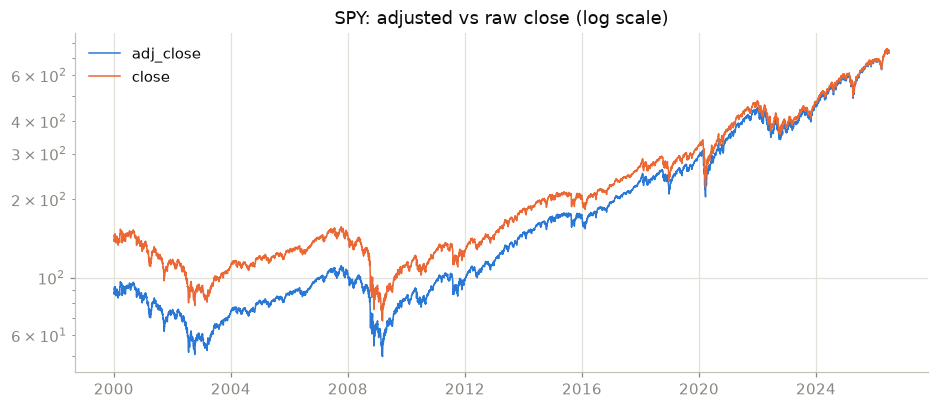

In [3]:
fig, ax = plt.subplots()
ax.plot(df.index, df["adj_close"], label="adj_close", lw=1)
ax.plot(df.index, df["close"], label="close", lw=1)
ax.set_yscale("log")
ax.set_title("SPY: adjusted vs raw close (log scale)")
ax.legend(frameon=False)
plt.show()

## Returns

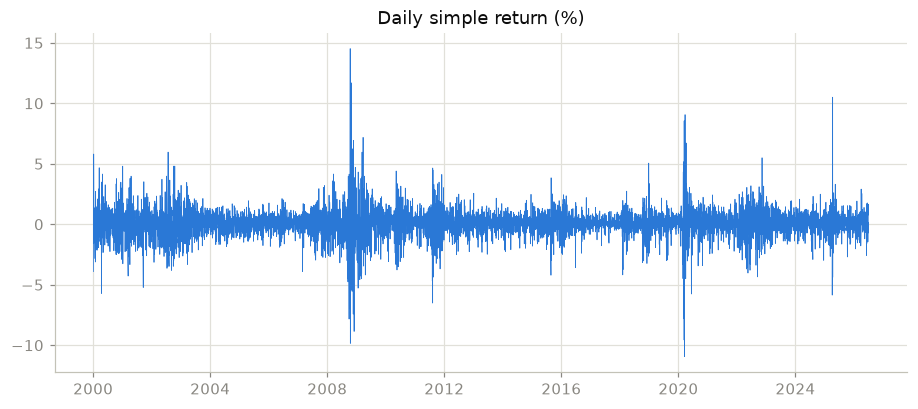

In [4]:
fig, ax = plt.subplots()
ax.plot(df.index, df["ret"] * 100, lw=0.5)
ax.set_title("Daily simple return (%)")
plt.show()

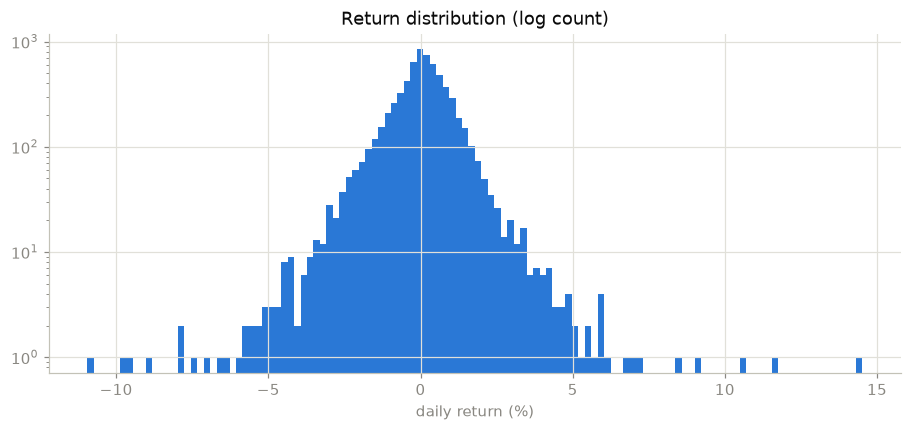

,mean,std,skew,kurt,min,max
ret,0.00039,0.012164,0.040017,12.046263,-0.109424,0.145198


In [5]:
fig, ax = plt.subplots()
ax.hist(df["ret"] * 100, bins=120, color=COLORS["blue"])
ax.set_yscale("log")
ax.set_title("Return distribution (log count)")
ax.set_xlabel("daily return (%)")
plt.show()

df["ret"].agg(["mean", "std", "skew", "kurt", "min", "max"]).to_frame("ret").T

In [6]:
worst, best = df["ret"].nsmallest(5), df["ret"].nlargest(5)
pd.DataFrame({"worst_day": worst.index.date, "worst_ret": worst.to_numpy(),
              "best_day": best.index.date, "best_ret": best.to_numpy()})

,worst_day,worst_ret,best_day,best_ret
0,2020-03-16,-0.109424,2008-10-13,0.145198
1,2008-10-15,-0.098448,2008-10-28,0.116855
2,2020-03-12,-0.095677,2025-04-09,0.105019
3,2008-12-01,-0.088579,2020-03-24,0.090603
4,2008-09-29,-0.078362,2020-03-13,0.085486


## Volatility preview

Rolling 21-day annualized vol of log returns, just for orientation. The daily Garman-Klass + overnight estimator (`realized_vol_gk`) is the next deliverable.

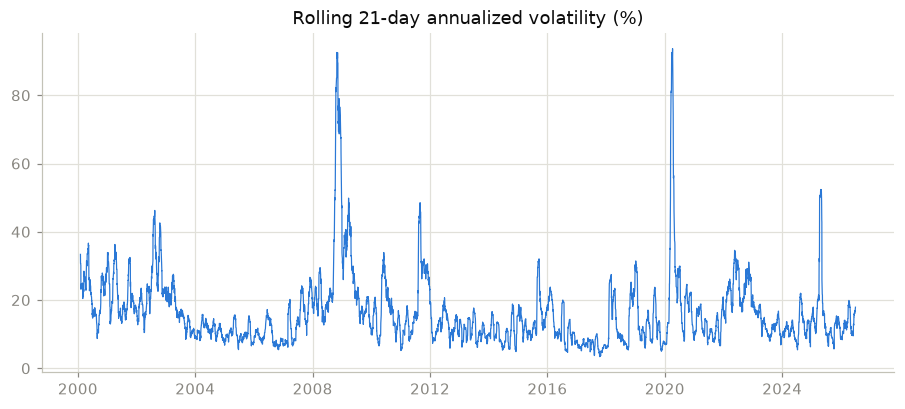

In [7]:
vol = df["log_ret"].rolling(21).std() * np.sqrt(252) * 100
fig, ax = plt.subplots()
ax.plot(vol.index, vol, lw=0.8)
ax.set_title("Rolling 21-day annualized volatility (%)")
plt.show()

## Dividends

Cash dividend per share on ex-dividend dates (2026 is a partial year).

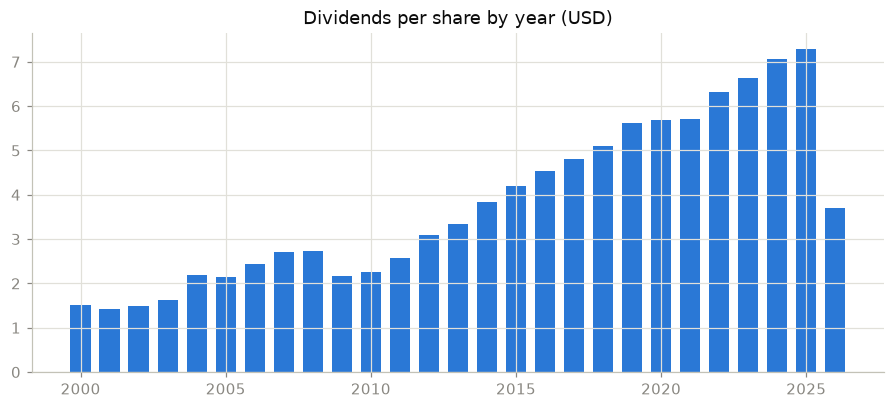

107 ex-dividend dates; median gap 91 days


In [8]:
divs = df.loc[df["dividend"] > 0, "dividend"]
per_year = divs.resample("YE").sum()
fig, ax = plt.subplots()
ax.bar(per_year.index.year, per_year, color=COLORS["blue"], width=0.7)
ax.set_title("Dividends per share by year (USD)")
plt.show()
print(f"{len(divs)} ex-dividend dates; median gap "
      f"{divs.index.to_series().diff().dt.days.median():.0f} days")

## Consistency checks

In [9]:
assert (np.abs(np.log1p(df["ret"]) - df["log_ret"]) < 1e-12).all()
factor = df["adj_close"] / df["close"]
print(f"adjustment factor: {factor.iloc[0]:.4f} (2000) -> {factor.iloc[-1]:.4f} (end)")
print("ret/log_ret agree; OHLC sanity and finiteness are enforced by the build")

adjustment factor: 0.6266 (2000) -> 1.0000 (end)
ret/log_ret agree; OHLC sanity and finiteness are enforced by the build
